## Assignment 1 - 12320 Hydrology
### Malthe Tretow-Loof (s242273)

### 0 Preparation

Firstly we import necessary packages and set up our Pandas from the provided data sheets.

In [1]:
from sympy import *
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

This command will read the data sheets granted that this notebook is located in the same folder as the data sheets. 

If an error occur, the specific file path for each data sheet can be inserted for their respective dataframe.

In [2]:
df1 = pd.read_excel(r"CAMELS_DK_obs_based_13230466.xlsx")
df2 = pd.read_excel(r"CAMELS_DK_obs_based_13230469.xlsx")
df3 = pd.read_excel(r"CAMELS_DK_obs_based_13230518.xlsx")
df4 = pd.read_excel(r"CAMELS_DK_obs_based_13230688.xlsx")

dfs = df1, df2, df3, df4

In [3]:
for df in dfs:
    df['catch_id'] = df['catch_id'].iloc[0]
    df['precip'] = df['precipitation']
    df['cum_precip'] = df['precipitation'].cumsum()
    df['ref_ET'] = df['pet']
    df['cum_ref_ET'] = df['pet'].cumsum()
    df['air_temp'] = df['temperature']
    df['obs_discharge'] = df['Qobs']
    df['sim_discharge'] = df['Qdkm']
    df['time'] = df['time']

In [4]:
colors = ['blue', 'red', 'green', 'orange']

### 1 Plot Precipitation, Cumulative Precipitation, Reference ET, Cumulative Reference ET, Air Temperature and Observed and Simulated Discharge as a Function of Time

To plot for multiple parameters it is effcient to set up a function which we may call upon to plot any of our measured parameters as a function of time.

In [5]:
def plot_catchment_data(dfs, colors, variable, ylabel, title):

    plt.figure()

    for df, color in zip(dfs, colors):
        plt.plot(df['time'], df[variable],
                 color=color,
                 label=f"{df['catch_id'].iloc[0]}")

    plt.xlabel('Time')
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.show()


**Precipitation**

We see that precipitation is largely consistent across catchments, with a few outliers of extreme precipitation affecting catchments differently on the day. This is likely due to local storms affecting some locations more than others. At the same time we do not see days of floods in one place with complete drought at others.

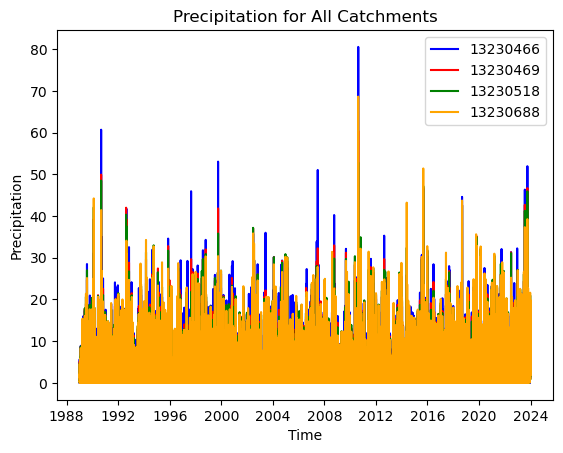

In [6]:
plot_catchment_data(
    dfs, colors,
    variable='precip',
    ylabel='Precipitation',
    title='Precipitation for All Catchments'
)

**Cumulative Percipitation**

Again all catchments follow each other closely, however we do see a ranking of total precipitation from highest to lowest being catchment 13230466, 13230469, 13230518 and 13230688.

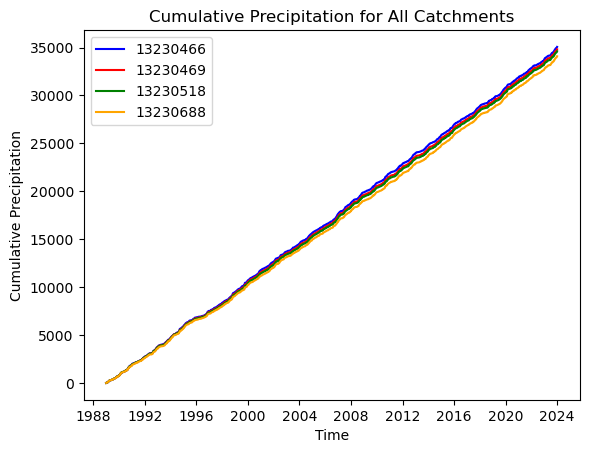

In [7]:
plot_catchment_data(
    dfs, colors,
    variable='cum_precip',
    ylabel='Cumulative Precipitation',
    title='Cumulative Precipitation for All Catchments'
)

**Reference ET**

Reference evaporationtransient is almost exactly the same across catchments and follow seasonal cycles across catchments.

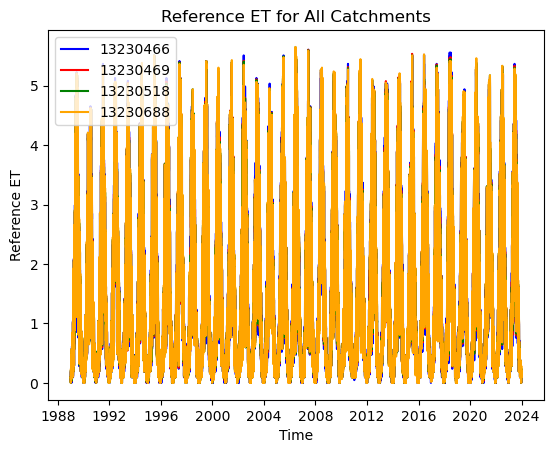

In [8]:
plot_catchment_data(
    dfs, colors,
    variable='ref_ET',
    ylabel='Reference ET',
    title='Reference ET for All Catchments'
)

**Cumulative Reference ET**

Cumulative ET is as expected, almost identical, just like reference ET above.

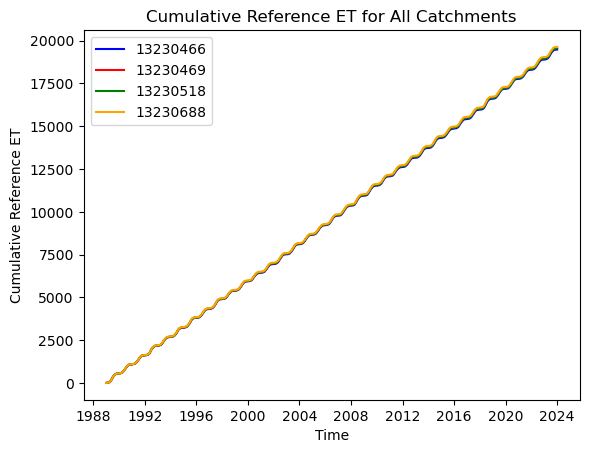

In [9]:
plot_catchment_data(
    dfs, colors,
    variable='cum_ref_ET',
    ylabel='Cumulative Reference ET',
    title='Cumulative Reference ET for All Catchments'
)

**Air Temperature**

Air temperature is like ET almost identical across catchments, which matches with the identical seasonal ET across catchments observed above.

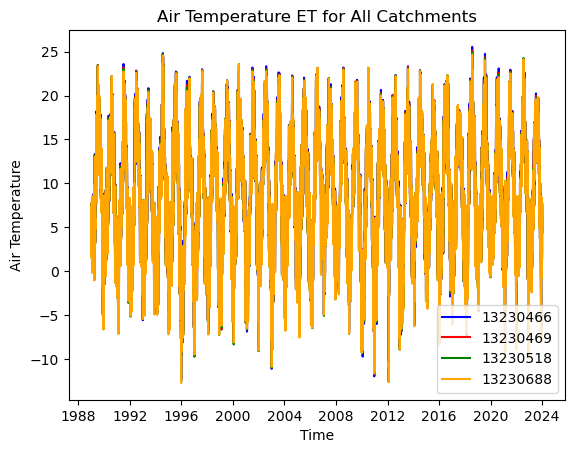

In [10]:
plot_catchment_data(
    dfs, colors,
    variable='air_temp',
    ylabel='Air Temperature',
    title='Air Temperature ET for All Catchments'
)

**Observed Discharge**

Observed discharge varies greatly across cathcments despite similar precipitation, however this is due to observed discharge not being normalized to cathcment size. By plotting total discharge volume per catchemnt we see the larger catchment have the largest discharge volumes, as expected.

We also see that we are missing data for some time periods across catchments.

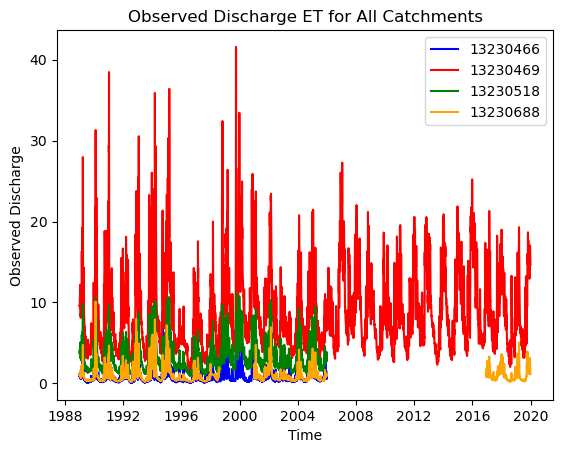

In [11]:
plot_catchment_data(
    dfs, colors,
    variable='obs_discharge',
    ylabel='Observed Discharge',
    title='Observed Discharge ET for All Catchments'
)

**Simulated Discharge**

The simulated discharge shows the data gaps filled out based on the availiable data. We see the data for all catchments has become more cyclical over time. This is espcecially clear for catchment 13230469 when comparring simulated date with the observed discharge above.

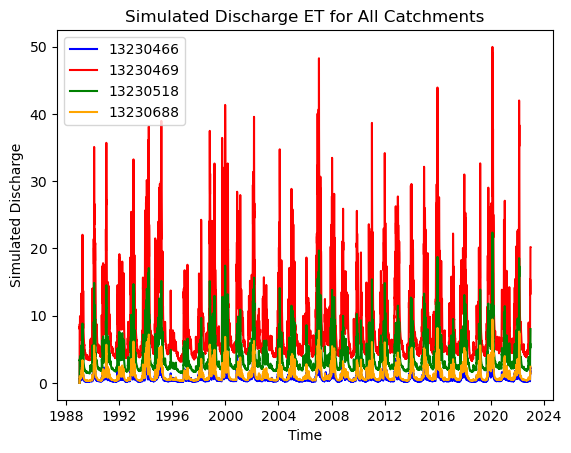

In [12]:
plot_catchment_data(
    dfs, colors,
    variable='sim_discharge',
    ylabel='Simulated Discharge',
    title='Simulated Discharge ET for All Catchments'
)

### 2 Mean, Standard Deviation and Coefficient of Variation of the Observed Discharge

We calcualte and plot the mean and standard deviation, and use these to calculate the coefficicent variance as followed:

$$ CV = \frac{\sigma}{\mu} $$

We see that the mean across catchments is genereally much closer to the minimum values despite frequent extremes in discharge. This shows us that the vast majority of the time, the flow is significatnly lower than during rare floodings.

The $+-$ standard deviation area covers most of the fluctuations in catchment 13230688, shwoing that the discharge volume more rarely exceeds normal values to the same extreme as other catchments.

We see that the coeffcient of variation for cathcment 13230466 and 13230688 we see them being above or close to 1. Meanig that the standard deviation and mean are almost the same. Thsi indicates a huge spread in the data and great range between the max and min values. This is logical when we see thast flooding events often exceed 6-8 times mean values.

For catchment 13230469 and 13230518 we see coeffcient of variation just abvoe 0.5, which indicates a somewhat lower spread in the data comapred to the two other cathcments, as extremes exceed 3-4 times the mean value.

In [13]:
for df in dfs:
    df['mean_obs_dis'] = df['obs_discharge'].mean()
    df['std_obs_dis'] = df['obs_discharge'].std()
    df['coef_var_obs_dis'] = df['std_obs_dis'] / df['mean_obs_dis']


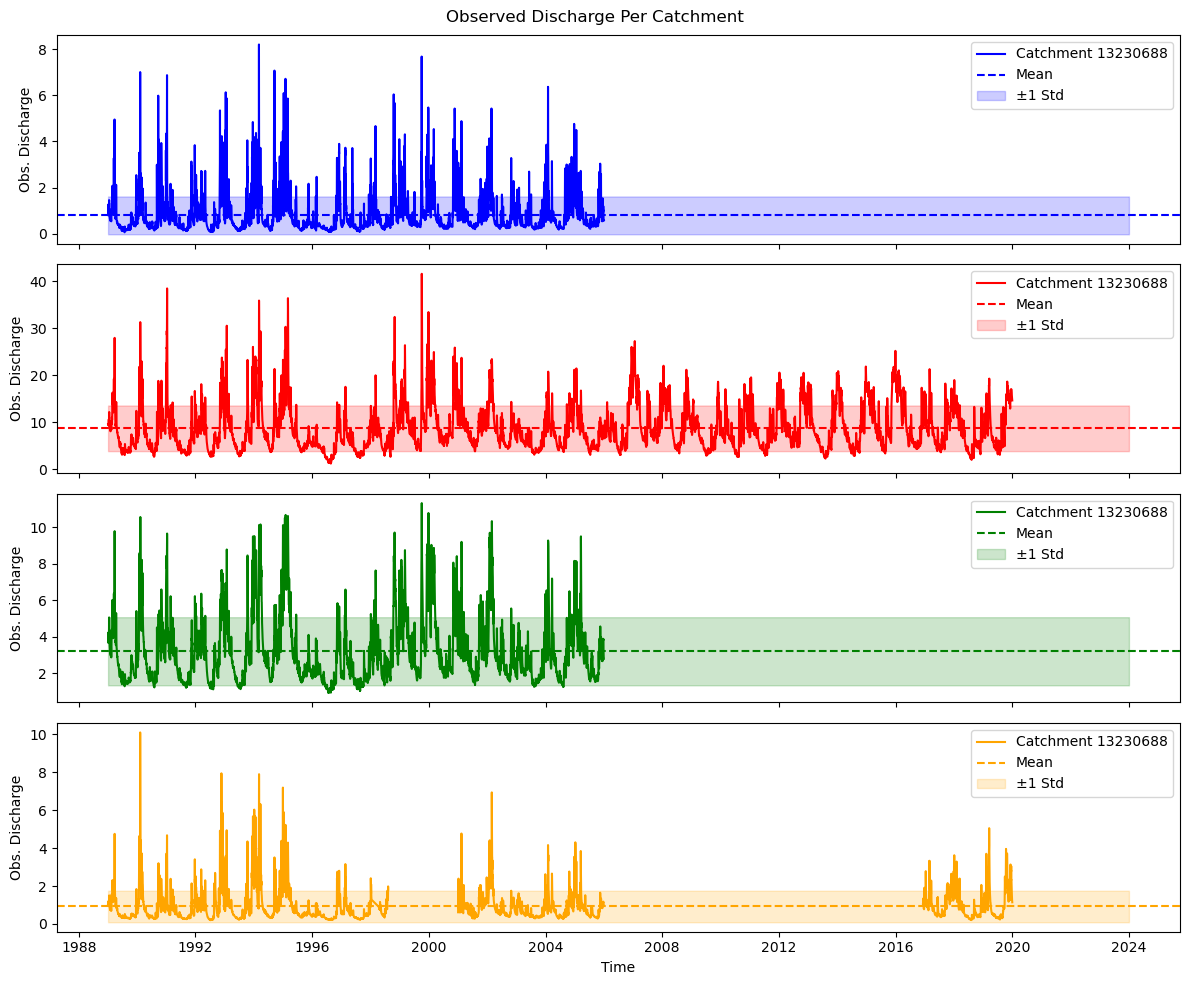

In [14]:

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for ax, df, color, cid in zip(axes, dfs, colors, df['catch_id']):

    mean_Q = df['obs_discharge'].mean()
    std_Q = df['obs_discharge'].std()

    # Plot discharge
    ax.plot(df['time'], df['obs_discharge'],
            color=color,
            label=f'Catchment {cid}')

    # Mean line
    ax.axhline(mean_Q, color=color, linestyle='--', label='Mean')

    # Std band
    ax.fill_between(
        df['time'],
        mean_Q - std_Q,
        mean_Q + std_Q,
        color=color,
        alpha=0.2,
        label='±1 Std'
    )

    ax.set_ylabel('Obs. Discharge')
    ax.legend()

axes[-1].set_xlabel('Time')

plt.suptitle('Observed Discharge Per Catchment')
plt.tight_layout()

plt.show()


In [15]:
for df in dfs:
    print(df[['catch_id', 'coef_var_obs_dis']].head(1))

   catch_id  coef_var_obs_dis
0  13230466          1.039417
   catch_id  coef_var_obs_dis
0  13230469          0.555095
   catch_id  coef_var_obs_dis
0  13230518          0.579019
   catch_id  coef_var_obs_dis
0  13230688          0.901073


### 3 Instantaneous Transient Water Balance

The transient water balance for a catchment is described through a differenfial equation showing the change in storage over change in time. The equation is constructed upon a mass balance describing inflows and outflows from the catchment. 

Inflows include precipitation (P) multiplied by the catchment area (A) to get a total volume.

Outflows include discharge (Q) describing af flux of outflowing water and evaporationtransient (ET) multiplied by catchment area (A) to get the volume lost to evaporation, analog to the precipitation calculation.

$$\frac{dSto}{dt} = P \cdot A - ET \cdot A - Q $$

For this assignment the catchments ground water exchnage (GWE) is not included in our data and thereby not included for this and following calculations.

### 4 Long-term Transient Water Balance

The long-term water balance for a catchment the change in net storage over time will approach 0. This is also described as steady state expressed by $inflow = outflow$ over the long-term. 

$$ \frac{dSto}{dt} \rightarrow 0 $$

This is physically supported as we can not have a physical negative quantity of water, and that catchments do not turn into lakes.

Thereby:

$$ \frac{dSto}{dt} = P \cdot A - ET \cdot A - Q $$

Becomes:

$$ 0 = P \cdot A - ET \cdot A - Q $$

### 5 Transient Water Balance - Computing Actual ETA

To solve for the average actual evaporationstransient for each cathcment we use the long-term water balance by simply isolating for ET in our equation above.

$$ 0 = P \cdot A - ET \cdot A - Q \rightarrow ET = P - \frac{Q}{A} $$

For this we need to save the cathcment area into our dataframe.

To get representative results, we create a sub-dataframe that exclude data for days where observed discharge (Q) is missing data.

We then convert our measurements to the unit mm/day.

For simplicity a Q_depth variable may be calculated for the term $\frac{Q}{A}$ seperately and then afterwards subtracted from precipitation (P).

In [16]:
# add additional data for catchments to dataframe
catch_size_map = {
    13230466: 6563 * 1e4,
    13230469: 62278 * 1e4,
    13230518: 27048 * 1e4,
    13230688: 11211 * 1e4
}

for df in dfs:
    cid = df['catch_id'].iloc[0]
    df['catch_size'] = catch_size_map[cid] #m2

In [17]:
results = []

for df in dfs:

    cid = df['catch_id'].iloc[0]

    # Remove rows with missing discharge
    df_valid = df[df['obs_discharge'].notna()].copy()

    # Convert discharge to depth (mm/day)
    Q_depth = (df_valid['obs_discharge'] * 86400) / df_valid['catch_size'] * 1000

    # Water balance
    actual_ET = df_valid['precip'] - Q_depth

    actual_ET_mean = actual_ET.mean()

    results.append({
        'catch_id': cid,
        'actual_ET_mean_mm_day': actual_ET_mean
    })


# Convert to dataframe
ET_table = pd.DataFrame(results)

print(ET_table)


   catch_id  actual_ET_mean_mm_day
0  13230466               1.617350
1  13230469               1.483343
2  13230518               1.569962
3  13230688               1.806038


### 6 Runoff-Coefficient

Run-off coefficient ($C_r$) is defined as the percentage of rainfall that becomes dicharge:

$$ C_r = \frac{\sum{Q}}{\sum{P}} \cdot 100 $$

We now need to ensure consistent units. To ahcieve this we convert dicharge to mm/day (Q_depth_daily) and then its sum in mm (Q_total), along with the sum of precipitation (P_total) before computing $C_r$.

In [18]:
runoff_results = []

for df in dfs:

    cid = df['catch_id'].iloc[0]

    A = df['catch_size'].iloc[0]  # m²

    # Total precipitation (mm)
    P_total = df['precip'].sum()

    # Convert discharge to runoff depth (mm/day)
    Q_depth_daily = (df['obs_discharge'] * 86400) / A * 1000

    # Total runoff depth (mm)
    Q_total = Q_depth_daily.sum()

    Cr = (Q_total / P_total) * 100

    runoff_results.append({
        "catch_id": cid,
        "Cr_percent": Cr
    })

Cr_df = pd.DataFrame(runoff_results)

print(Cr_df)


   catch_id  Cr_percent
0  13230466   18.399379
1  13230469   39.391475
2  13230518   18.413444
3  13230688   13.435880


### 7 Discrete Transient Water Balance

To reformulate the transient water balance for discrete daily time steps we convert the water balance equation to be based upon the difference between storage 1 time step into the future minus current storage, over the difference in time.

This may also be expressed as followed with $i$ representing a time step:

$$ \frac{dSto}{dt} \rightarrow \frac {Sto_{i+1} - Sto_i}{\Delta{t}} $$

Applying this to our water balance equation we see the following:

$$ Sto_{i+1} - Sto_i = (P_iA - ET_iA-Q) \Delta{t} $$

Which we can rewrite to:

$$ Sto_{i+1} = Sto_i + (P_iA - ET_iA-Q) \Delta{t} $$

### 8 Flow Duration Curve

We construct the flow duration curve by sorting observed discharge values from highest to lowest and assigning each value an exceedance probability based on its rank. This is also the x-axis of our FDC.

$$ Exceedance \; probability = \frac{1}{days} \cdot 100 $$

The curve describes how often different flow magnitudes occur. Observed discharge volume exceeded 50% of the time represent typical flows, very low exceedance probabilities represent rare floods and very high exceedance probability represents drought.

We can now begin computing the correlating discharge volumes to the exceeded probabilities using the FDC. We do this by setting up a for loop with our caluclated probabilites as target porbabilites. 

We then go through the probability for each discharge, beginning with the largest, and calculate the difference between the probaility of this specific discharge value's exceedance possibility to our target probability, and save the discharge value. 

We then go through the next discharge value and compare difference in exceedance possibility again. If the new discharge value has a smaller difference in possibility to the previosly saved discharge value, we replace the saved discharge value with the new one that has a closer exceedance probability to our target probability. This allows us to walk towards the discharge value with the closest exceedance probability to our target probability.

**Interpretation**

From the values we see for the discharge values that on average are exceeded every 2 days, week, month and year. From this we identify a flooding dicharge value of 28.6 m3/s at exceedence probaility of 0.27%. This is extremely low, and may be classified as very high-flow or flood. We see that this fits with the plot of observed discharge over time for catchment 13230469 in question 1, where this value is exceeded at least 8 times from 1988-2020. In respect to our time frame, this confirms that this is a level that is very rarely exceeded.

Fromthe time periods we have examined, we do not get a discharge value with exceedance probability above 90-95% which we would use to classify a drought directly. Looking at the same graph in question 1 we can however see minimums at around 3 m3/s and is exceeded the vast majority of the time during the peirod 1988-2020, thereby depiciting a very high exceedance probability, which we use to qualify droughts.

In [19]:
for df in dfs:
    if df['catch_id'].iloc[0] == 13230469:
        df_station = df
        break

# Remove missing discharge values
Q = df_station['obs_discharge'].dropna().values

# Sort discharge (largest → smallest)
Q_sorted = np.sort(Q)[::-1]

# Exceedance probability (%)
n = len(Q_sorted)
exceed_prob = np.arange(1, n+1) / (n+1) * 100

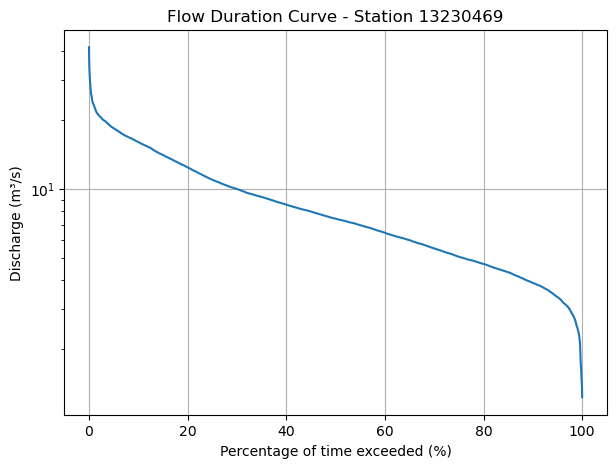

In [20]:
plt.figure(figsize=(7,5))
plt.plot(exceed_prob, Q_sorted)
plt.yscale('log')
plt.xlabel('Percentage of time exceeded (%)')
plt.ylabel('Discharge (m³/s)')
plt.title('Flow Duration Curve - Station 13230469')
plt.grid(True)
plt.show()


In [21]:
days_list = [2, 7, 30, 365]

exceedance_targets = []

for days in days_list:
    percent = 100 / days
    exceedance_targets.append(percent)

In [22]:
results = []

for days, target_percent in zip(days_list, exceedance_targets):

    smallest_difference = abs(exceed_prob[0] - target_percent)
    closest_index = 0

    for i in range(len(exceed_prob)):
        difference = abs(exceed_prob[i] - target_percent)

        if difference < smallest_difference:
            smallest_difference = difference
            closest_index = i

    discharge_value = Q_sorted[closest_index]

    results.append({
        "days": days,
        "exceedance_percent": target_percent,
        "discharge_m3s": discharge_value
    })

fdc_results = pd.DataFrame(results)
print(fdc_results)

   days  exceedance_percent  discharge_m3s
0     2           50.000000         7.4240
1     7           14.285714        14.3155
2    30            3.333333        19.7553
3   365            0.273973        28.5770


### **Declaration of AI**

This notebook has been developed for assignment 2 in the course 12320 Hydrology F26 at DTU Lyngby.

This assingment has been produced with the use of ChatGPT model 5.2 during February of 2026.

The AI has been used to help with data infrastructure setup, syntax errors and generel coding assistance.

All contents of this notebook have been read, reviewed and edited to ensure it represents the understanding of the students of admission and fulfills assignment requirements. 

The students of admission takes full responsibility for the contents of this notebook.